# Sokoban: does the assistance dilemma appear?

The Rush Hour notebooks (`p4_dilemma.ipynb` to `p6_hindsight.ipynb`) found an assistance dilemma: with shortcut
labels, a student shown every move learns less than one shown 30% (agency 1: −0.29, 0 of 8 students better), because
fully shown play leaves the student nothing of its own to learn from. With own labels (the path played, loops cut),
more help was always better.

This notebook asks the same question in Sokoban, on Boxoban levels, with the `sokoban/` port:

- **Student** (`sokoban/student.py`): a policy network over pushes (walls, goals, boxes and the player's reachable
  region in; a push per cell and direction out, plus a value head). It samples pushes at temperature 1, avoids its
  last 10 boards, and restarts the level when its quick deadlock test fires. Pushes can't be undone, so unlike Rush
  Hour a wrong push can end the attempt's chances.
- **Labels**: *shortcut labels* ("all", as in Rush Hour) are the shortest routes through every board the attempt
  visited, restarts included; *own labels* are the winning path since the last restart, loops cut. Pushes the
  teacher showed teach too. Agency is 1: a shown push counts as much as the student's own.
- **Teacher** (`sokoban/teach.py`): `Random(p)` shows the optimal push on each turn with probability p.
- **Sessions** (`sokoban/sessions.py`): 8 students per teacher, each playing the same 2,000 Boxoban medium levels
  (500 each with 8-11, 12-15, 16-19 and 20-25 optimal pushes) in its own order, one attempt each, capped at 5x
  optimal (at least 50 pushes). It learns online after every 25 levels (3 passes over that block's examples, Adam,
  lr 1e-4). Student s gets the same order and random numbers under every teacher, so teachers compare student by
  student.
- **Tests**: every 500 levels, each student plays 200 held-out levels (50 per bin) three times, untaught. A test
  attempt scores pushes / optimal, an unsolved attempt counted at its cap (lower is better), as in the Rush Hour
  notebooks. **Learning** is the start score minus the end score.

## Where the students start

Every student starts from the same network, pretrained with `python sessions.py pretrain --teacher random:0.5`:
5,400 separate Boxoban medium levels with a teacher showing half the pushes (lr 1e-3). It solves about 12% of the
held-out levels untaught. Two settings were fixed along the way:

- Pretraining with p = 0.2 never got going (0-1% solved after 2,400 levels), while p = 1 and p = 0.5 reached
  13-18% by 5,400.
- In the first session run, a student with no teacher got *worse* (held-out solve rate 0.12 to 0.06). A 1,000-level
  probe from the same start pinned it on the learning rate and BatchNorm: 0.06 at lr 1e-3 with BatchNorm statistics
  updating on each block, 0.20 at lr 1e-4 (Rush Hour's), 0.225 at lr 1e-4 with BatchNorm frozen. The runs use lr 1e-4
  with BatchNorm frozen (`--freeze-norm 1`).

In [1]:
import os
import sys

sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import pandas as pd

import session_analysis as sa

FIGURES = "figures/s1_teaching"
os.makedirs(FIGURES, exist_ok=True)
RUNS = {"all": "shortcut_all", "own": "own_all"}  # label setting: run name (models/sessions/<run>)
runs = {labels: sa.load(name) for labels, name in RUNS.items()}
pd.options.display.float_format = "{:.3f}".format
for labels, run in runs.items():
    if run is None:
        print(f"{RUNS[labels]}: not finished yet")
    else:
        s0, solved0 = sa.start(run)
        print(f"{RUNS[labels]}: start score {s0:.2f}, start solve rate {solved0:.3f}, "
              f"teachers {', '.join(sa.teacher_name(t) for t in run['teachers'])}")

shortcut_all: start score 4.74, start solve rate 0.133, teachers no teacher, random 0.1, random 0.3, random 1, guard 1, guard 0.3, undo 1, undo 0.3, restart dead, restart 1.5, undo+restart 1.5
own_all: start score 4.74, start solve rate 0.133, teachers no teacher, random 0.1, random 0.3, random 1

## Shortcut labels

The Rush Hour dilemma condition. *Pushes shown* is the share of all session pushes the teacher showed; *solved as
played* is the share of session levels solved during the session, with the teacher's help. *Learning* and the end
solve rate are means over the 8 students, with standard errors.

,pushes shown,solved as played,end solve rate,end solve rate se,learning,learning se
teacher,,,,,,
no teacher,0.000,0.220,0.246,0.005,0.335,0.017
random 0.1,0.058,0.232,0.180,0.003,0.105,0.012
random 0.3,0.189,0.428,0.173,0.004,0.084,0.011
random 1,1.000,1.000,0.220,0.003,0.232,0.016
guard 1,0.180,0.949,0.219,0.005,0.225,0.012
guard 0.3,0.037,0.309,0.192,0.005,0.151,0.013
undo 1,0.406,0.893,0.228,0.004,0.253,0.007
undo 0.3,0.039,0.310,0.249,0.005,0.350,0.012
restart dead,0.178,0.299,0.253,0.006,0.340,0.017


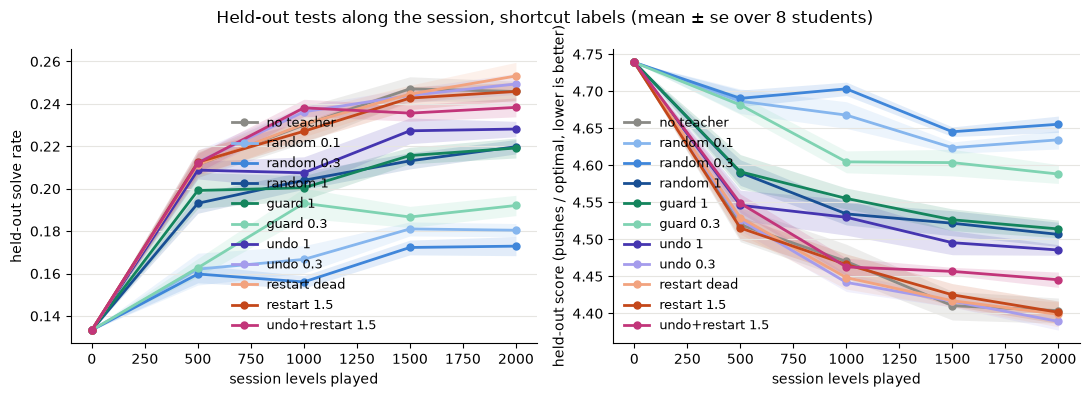

End score, row minus column, paired by student (below 0: the row's students learned more; in brackets, students better in the row):

,no teacher,random 0.1,random 0.3,random 1,guard 1,guard 0.3,undo 1,undo 0.3,restart dead,restart 1.5,undo+restart 1.5
no teacher,,-0.23 ± 0.01 (8/8),-0.25 ± 0.01 (8/8),-0.10 ± 0.01 (8/8),-0.11 ± 0.02 (8/8),-0.18 ± 0.02 (8/8),-0.08 ± 0.02 (8/8),+0.01 ± 0.02 (2/8),+0.01 ± 0.02 (2/8),+0.00 ± 0.03 (4/8),-0.04 ± 0.02 (6/8)
random 0.1,+0.23 ± 0.01 (0/8),,-0.02 ± 0.01 (6/8),+0.13 ± 0.02 (0/8),+0.12 ± 0.02 (0/8),+0.05 ± 0.01 (1/8),+0.15 ± 0.02 (0/8),+0.25 ± 0.02 (0/8),+0.24 ± 0.02 (0/8),+0.23 ± 0.02 (0/8),+0.19 ± 0.01 (0/8)
random 0.3,+0.25 ± 0.01 (0/8),+0.02 ± 0.01 (2/8),,+0.15 ± 0.01 (0/8),+0.14 ± 0.02 (0/8),+0.07 ± 0.02 (1/8),+0.17 ± 0.01 (0/8),+0.27 ± 0.02 (0/8),+0.26 ± 0.02 (0/8),+0.25 ± 0.02 (0/8),+0.21 ± 0.01 (0/8)
random 1,+0.10 ± 0.01 (0/8),-0.13 ± 0.02 (8/8),-0.15 ± 0.01 (8/8),,-0.01 ± 0.02 (5/8),-0.08 ± 0.02 (8/8),+0.02 ± 0.02 (2/8),+0.12 ± 0.02 (0/8),+0.11 ± 0.02 (0/8),+0.11 ± 0.03 (1/8),+0.06 ± 0.02 (1/8)
guard 1,+0.11 ± 0.02 (0/8),-0.12 ± 0.02 (8/8),-0.14 ± 0.02 (8/8),+0.01 ± 0.02 (3/8),,-0.07 ± 0.02 (8/8),+0.03 ± 0.01 (2/8),+0.12 ± 0.02 (0/8),+0.12 ± 0.02 (0/8),+0.11 ± 0.02 (0/8),+0.07 ± 0.01 (1/8)
guard 0.3,+0.18 ± 0.02 (0/8),-0.05 ± 0.01 (7/8),-0.07 ± 0.02 (7/8),+0.08 ± 0.02 (0/8),+0.07 ± 0.02 (0/8),,+0.10 ± 0.01 (0/8),+0.20 ± 0.02 (0/8),+0.19 ± 0.01 (0/8),+0.19 ± 0.02 (0/8),+0.14 ± 0.02 (0/8)
undo 1,+0.08 ± 0.02 (0/8),-0.15 ± 0.02 (8/8),-0.17 ± 0.01 (8/8),-0.02 ± 0.02 (6/8),-0.03 ± 0.01 (6/8),-0.10 ± 0.01 (8/8),,+0.10 ± 0.01 (0/8),+0.09 ± 0.01 (0/8),+0.08 ± 0.01 (0/8),+0.04 ± 0.01 (1/8)
undo 0.3,-0.01 ± 0.02 (6/8),-0.25 ± 0.02 (8/8),-0.27 ± 0.02 (8/8),-0.12 ± 0.02 (8/8),-0.12 ± 0.02 (8/8),-0.20 ± 0.02 (8/8),-0.10 ± 0.01 (8/8),,-0.01 ± 0.03 (4/8),-0.01 ± 0.02 (4/8),-0.06 ± 0.02 (7/8)
restart dead,-0.01 ± 0.02 (6/8),-0.24 ± 0.02 (8/8),-0.26 ± 0.02 (8/8),-0.11 ± 0.02 (8/8),-0.12 ± 0.02 (8/8),-0.19 ± 0.01 (8/8),-0.09 ± 0.01 (8/8),+0.01 ± 0.03 (4/8),,-0.00 ± 0.02 (4/8),-0.05 ± 0.02 (5/8)
restart 1.5,-0.00 ± 0.03 (4/8),-0.23 ± 0.02 (8/8),-0.25 ± 0.02 (8/8),-0.11 ± 0.03 (7/8),-0.11 ± 0.02 (8/8),-0.19 ± 0.02 (8/8),-0.08 ± 0.01 (8/8),+0.01 ± 0.02 (4/8),+0.00 ± 0.02 (4/8),,-0.04 ± 0.02 (6/8)


In [2]:
def section(labels):
    run = runs[labels]
    if run is None:
        print(f"{RUNS[labels]} hasn't finished")
        return
    display(sa.teacher_table(run))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    sa.plot_curves(axes[0], run, "solve rate")
    sa.plot_curves(axes[1], run, "score")
    fig.suptitle(f"Held-out tests along the session, {sa.LABEL_NAMES[labels]} (mean ± se over 8 students)")
    fig.tight_layout()
    fig.savefig(f"{FIGURES}/curves_{labels}.png", dpi=130)
    plt.show()
    print("End score, row minus column, paired by student (below 0: the row's students learned more; "
          "in brackets, students better in the row):")
    display(sa.paired_table(run))


section("all")

## Own labels

The Rush Hour contrast: the student learns only from its winning path (since the last restart, loops cut) and from
pushes it was shown, not from shortcuts across its wandering.

,pushes shown,solved as played,end solve rate,end solve rate se,learning,learning se
teacher,,,,,,
no teacher,0.000,0.216,0.247,0.004,0.344,0.012
random 0.1,0.058,0.223,0.166,0.005,0.074,0.012
random 0.3,0.188,0.423,0.175,0.004,0.094,0.010
random 1,1.000,1.000,0.221,0.005,0.229,0.013


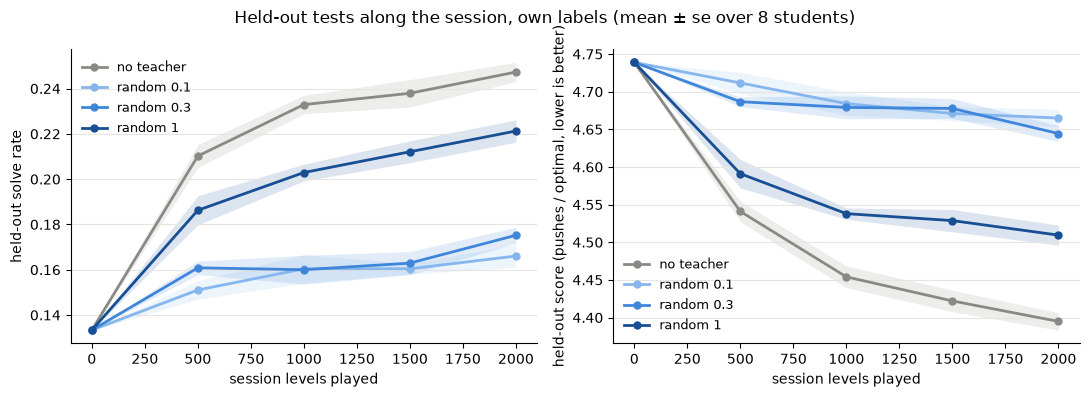

End score, row minus column, paired by student (below 0: the row's students learned more; in brackets, students better in the row):

,no teacher,random 0.1,random 0.3,random 1
no teacher,,-0.27 ± 0.02 (8/8),-0.25 ± 0.01 (8/8),-0.11 ± 0.02 (8/8)
random 0.1,+0.27 ± 0.02 (0/8),,+0.02 ± 0.02 (4/8),+0.16 ± 0.02 (0/8)
random 0.3,+0.25 ± 0.01 (0/8),-0.02 ± 0.02 (4/8),,+0.13 ± 0.01 (0/8)
random 1,+0.11 ± 0.02 (0/8),-0.16 ± 0.02 (8/8),-0.13 ± 0.01 (8/8),


In [3]:
section("own")

## A deadlock guard

`teach.Guard(q)` steps in only when the student is one push from a deadlock: when the push it is about to play would
leave the level unsolvable (by the oracle), it shows the optimal push instead, with probability q. Anywhere else the
student plays alone. Like Rush Hour's `CorrectMistakes`, it sees the push the student intends, an idealization. With
q = 1 the student never reaches a deadlocked board, so it never restarts. The guards play in the shortcut-label run,
with the same 8 students and levels as the other teachers.

,pushes shown,solved as played,end solve rate,end solve rate se,learning,learning se
teacher,,,,,,
no teacher,0.000,0.220,0.246,0.005,0.335,0.017
random 1,1.000,1.000,0.220,0.003,0.232,0.016
guard 0.3,0.037,0.309,0.192,0.005,0.151,0.013
guard 1,0.180,0.949,0.219,0.005,0.225,0.012


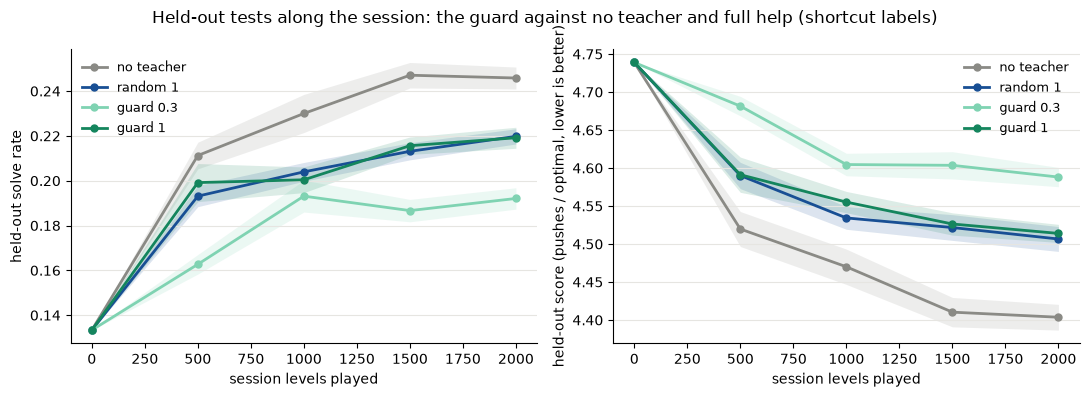

End score, row minus column, paired by student (below 0: the row's students learned more):

,no teacher,random 1,guard 0.3,guard 1
no teacher,,-0.10 ± 0.01 (8/8),-0.18 ± 0.02 (8/8),-0.11 ± 0.02 (8/8)
random 1,+0.10 ± 0.01 (0/8),,-0.08 ± 0.02 (8/8),-0.01 ± 0.02 (5/8)
guard 0.3,+0.18 ± 0.02 (0/8),+0.08 ± 0.02 (0/8),,+0.07 ± 0.02 (0/8)
guard 1,+0.11 ± 0.02 (0/8),+0.01 ± 0.02 (3/8),-0.07 ± 0.02 (8/8),


In [4]:
run = runs["all"]
GUARD = [t for t in ["none", "random:1", "guard:0.3", "guard:1"] if len(run["teachers"].get(t, {})) == 8]
if any(t.startswith("guard") for t in GUARD):
    table = sa.teacher_table(run)
    display(table.loc[[sa.teacher_name(t) for t in GUARD]])
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    sa.plot_curves(axes[0], run, "solve rate", GUARD)
    sa.plot_curves(axes[1], run, "score", GUARD)
    fig.suptitle("Held-out tests along the session: the guard against no teacher and full help (shortcut labels)")
    fig.tight_layout()
    fig.savefig(f"{FIGURES}/curves_guard.png", dpi=130)
    plt.show()
    print("End score, row minus column, paired by student (below 0: the row's students learned more):")
    display(sa.paired_table(run, GUARD))
else:
    print("the guard runs haven't finished")

## Learning from dead ends: negative labels

So far a deadlock teaches the student nothing: it restarts, and the stretch that led there is never labelled. With
`--negative-weight 1` (`student.fatal_pushes`), the push it played right before its quick test caught a deadlock
becomes a negative label: "not this push here", learned by unlikelihood (−log(1 − p(push))), which lowers that push
without saying which other push is right. The run `shortcut_neg` repeats the shortcut-label run with negative labels,
with the same students, levels and seeds, so each teacher compares student by student across the two runs. Random 1
and guard 1 never let the student deadlock, so they would be unchanged and are not rerun.

,pushes shown,solved as played,end solve rate,end solve rate se,learning,learning se
teacher,,,,,,
no teacher,0.000,0.123,0.112,0.004,-0.078,0.013
random 0.1,0.056,0.188,0.132,0.003,-0.014,0.010
random 0.3,0.187,0.411,0.151,0.005,0.031,0.014
guard 0.3,0.036,0.263,0.136,0.004,0.004,0.012


Learning without and with negative labels; difference = with minus without, paired by student:

,pushes shown,learning,"learning, other",difference,difference se,students better
teacher,,,,,,
no teacher,0.000,0.335,-0.078,-0.414,0.020,0/8
random 0.1,0.056,0.105,-0.014,-0.118,0.012,0/8
random 0.3,0.187,0.084,0.031,-0.053,0.017,0/8
guard 0.3,0.036,0.151,0.004,-0.147,0.019,0/8


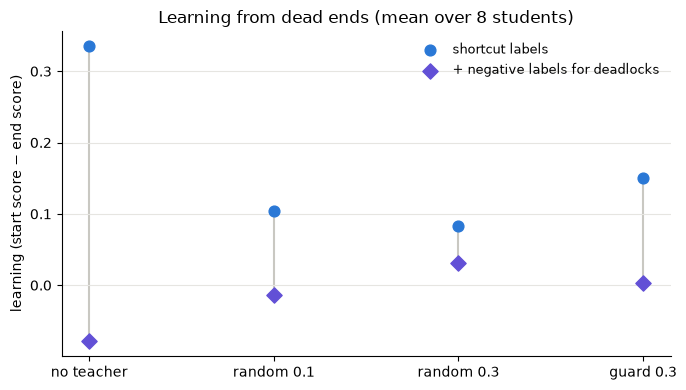

With negative labels: end score, row minus column, paired by student:

,no teacher,random 0.1,random 0.3,guard 0.3
no teacher,,+0.06 ± 0.02 (1/8),+0.11 ± 0.02 (0/8),+0.08 ± 0.01 (0/8)
random 0.1,-0.06 ± 0.02 (7/8),,+0.04 ± 0.02 (2/8),+0.02 ± 0.01 (2/8)
random 0.3,-0.11 ± 0.02 (8/8),-0.04 ± 0.02 (6/8),,-0.03 ± 0.02 (6/8)
guard 0.3,-0.08 ± 0.01 (8/8),-0.02 ± 0.01 (6/8),+0.03 ± 0.02 (2/8),


In [5]:
neg = sa.load("shortcut_neg")
if neg is None:
    print("shortcut_neg hasn't finished")
else:
    display(sa.teacher_table(neg))
    table = sa.cross_run_table(runs["all"], neg)
    print("Learning without and with negative labels; difference = with minus without, paired by student:")
    display(table)
    fig, ax = plt.subplots(figsize=(7, 4))
    sa.plot_cross_run(ax, table, "shortcut labels", "+ negative labels for deadlocks")
    ax.set_title("Learning from dead ends (mean over 8 students)")
    fig.tight_layout()
    fig.savefig(f"{FIGURES}/negative_labels.png", dpi=130)
    plt.show()
    print("With negative labels: end score, row minus column, paired by student:")
    display(sa.paired_table(neg))

## Taking the push back: the undo teacher

`teach.Undo(q)` catches the same pushes as the guard (ones that would leave a solvable level unsolvable), but shows
nothing: it takes the push back, with probability q, and the student chooses again from its own policy without it.
Every push it ends up playing is its own, so a solved attempt's labels describe the student's own play rather than a
route the teacher steered. That is the nearest Sokoban gets to Rush Hour, where a bad move can simply be undone. A push
taken back doesn't count toward the push budget. In the tables, "pushes shown" counts pushes taken back for the undo
teacher. The undo students play in the shortcut-label run, paired with every other teacher.

,pushes shown,solved as played,end solve rate,end solve rate se,learning,learning se
teacher,,,,,,
no teacher,0.000,0.220,0.246,0.005,0.335,0.017
guard 0.3,0.037,0.309,0.192,0.005,0.151,0.013
guard 1,0.180,0.949,0.219,0.005,0.225,0.012
undo 0.3,0.039,0.310,0.249,0.005,0.350,0.012
undo 1,0.406,0.893,0.228,0.004,0.253,0.007


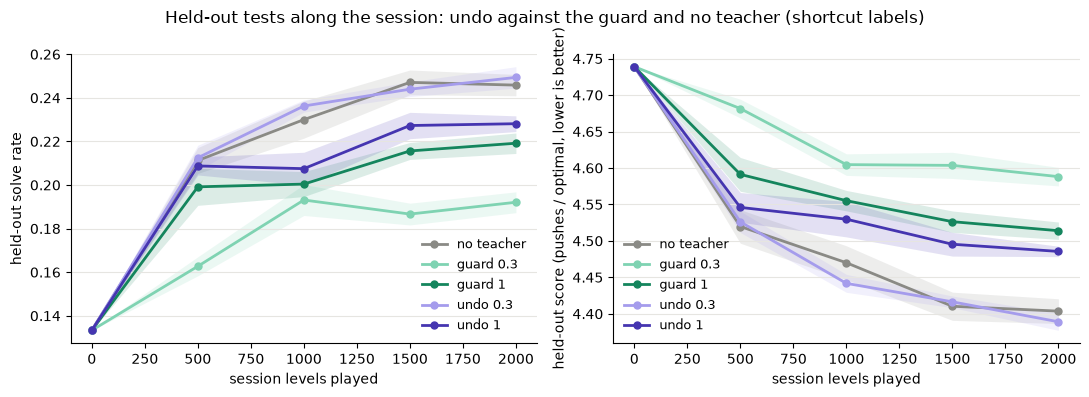

End score, row minus column, paired by student (below 0: the row's students learned more):

,no teacher,guard 0.3,guard 1,undo 0.3,undo 1
no teacher,,-0.18 ± 0.02 (8/8),-0.11 ± 0.02 (8/8),+0.01 ± 0.02 (2/8),-0.08 ± 0.02 (8/8)
guard 0.3,+0.18 ± 0.02 (0/8),,+0.07 ± 0.02 (0/8),+0.20 ± 0.02 (0/8),+0.10 ± 0.01 (0/8)
guard 1,+0.11 ± 0.02 (0/8),-0.07 ± 0.02 (8/8),,+0.12 ± 0.02 (0/8),+0.03 ± 0.01 (2/8)
undo 0.3,-0.01 ± 0.02 (6/8),-0.20 ± 0.02 (8/8),-0.12 ± 0.02 (8/8),,-0.10 ± 0.01 (8/8)
undo 1,+0.08 ± 0.02 (0/8),-0.10 ± 0.01 (8/8),-0.03 ± 0.01 (6/8),+0.10 ± 0.01 (0/8),


In [6]:
run = runs["all"]
UNDO = [t for t in ["none", "guard:0.3", "guard:1", "undo:0.3", "undo:1"] if len(run["teachers"].get(t, {})) == 8]
if any(t.startswith("undo") for t in UNDO):
    table = sa.teacher_table(run)
    display(table.loc[[sa.teacher_name(t) for t in UNDO]])
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    sa.plot_curves(axes[0], run, "solve rate", UNDO)
    sa.plot_curves(axes[1], run, "score", UNDO)
    fig.suptitle("Held-out tests along the session: undo against the guard and no teacher (shortcut labels)")
    fig.tight_layout()
    fig.savefig(f"{FIGURES}/curves_undo.png", dpi=130)
    plt.show()
    print("End score, row minus column, paired by student (below 0: the row's students learned more):")
    display(sa.paired_table(run, UNDO))
else:
    print("the undo runs haven't finished")

## Forcing a restart: the restart teacher

`teach.Restart(k)` shows nothing and takes nothing back: it only sends the student back to the start. It does so on a
board the oracle calls deadlocked (the student's quick test hasn't noticed, so it would play on), and, with finite k,
once the stretch can no longer finish within k × optimal pushes (pushes so far + distance to solved > k × optimal),
so every labelled win is within k of optimal. `undo+restart:k` also takes back every deadlocking push, as undo 1, so
the student never deadlocks and restarts only for straying. Here "pushes shown" counts restarts forced.

,pushes shown,solved as played,end solve rate,end solve rate se,learning,learning se
teacher,,,,,,
no teacher,0.000,0.220,0.246,0.005,0.335,0.017
undo 1,0.406,0.893,0.228,0.004,0.253,0.007
restart dead,0.178,0.299,0.253,0.006,0.340,0.017
restart 1.5,0.186,0.277,0.246,0.004,0.338,0.015
undo+restart 1.5,0.366,0.748,0.238,0.004,0.294,0.010


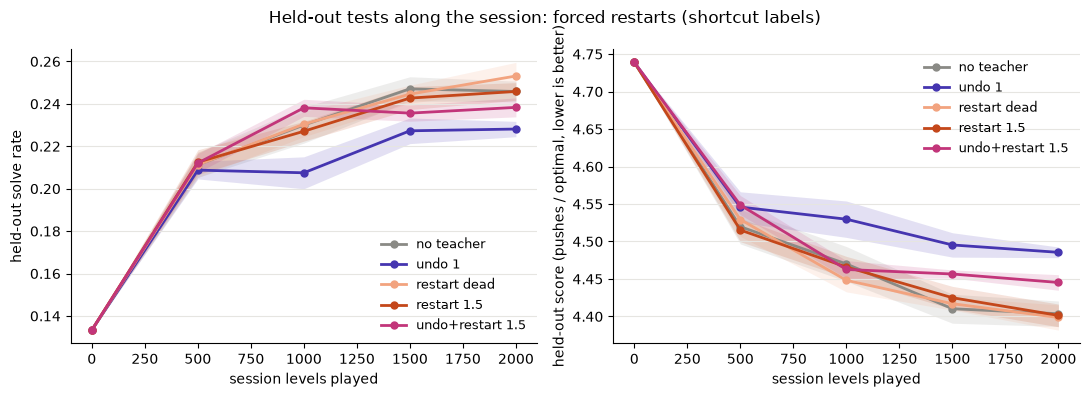

End score, row minus column, paired by student (below 0: the row's students learned more):

,no teacher,undo 1,restart dead,restart 1.5,undo+restart 1.5
no teacher,,-0.08 ± 0.02 (8/8),+0.01 ± 0.02 (2/8),+0.00 ± 0.03 (4/8),-0.04 ± 0.02 (6/8)
undo 1,+0.08 ± 0.02 (0/8),,+0.09 ± 0.01 (0/8),+0.08 ± 0.01 (0/8),+0.04 ± 0.01 (1/8)
restart dead,-0.01 ± 0.02 (6/8),-0.09 ± 0.01 (8/8),,-0.00 ± 0.02 (4/8),-0.05 ± 0.02 (5/8)
restart 1.5,-0.00 ± 0.03 (4/8),-0.08 ± 0.01 (8/8),+0.00 ± 0.02 (4/8),,-0.04 ± 0.02 (6/8)
undo+restart 1.5,+0.04 ± 0.02 (2/8),-0.04 ± 0.01 (7/8),+0.05 ± 0.02 (3/8),+0.04 ± 0.02 (2/8),


In [7]:
RESTART = [t for t in ["none", "undo:1", "restart:inf", "restart:1.5", "undo+restart:1.5"]
           if len(run["teachers"].get(t, {})) == 8]
if any("restart" in t for t in RESTART):
    table = sa.teacher_table(run)
    display(table.loc[[sa.teacher_name(t) for t in RESTART]])
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    sa.plot_curves(axes[0], run, "solve rate", RESTART)
    sa.plot_curves(axes[1], run, "score", RESTART)
    fig.suptitle("Held-out tests along the session: forced restarts (shortcut labels)")
    fig.tight_layout()
    fig.savefig(f"{FIGURES}/curves_restart.png", dpi=130)
    plt.show()
    print("End score, row minus column, paired by student (below 0: the row's students learned more):")
    display(sa.paired_table(run, RESTART))
else:
    print("the restart runs haven't finished")

## The step budget: equal and smaller batches

Each update makes 3 passes over its block's examples in batches of up to 256, so any block under 256 examples gets
exactly 3 Adam steps, and an Adam step is roughly the same size whatever it averages over. Two reruns, with the same
students, levels and seeds, change only the batching. `shortcut_even` (`--even-batches 1`, Rush Hour's fix) splits a
block into equal batches instead of full ones plus a remainder, keeping the step count. `shortcut_b64`
(`--batch-size 64 --even-batches 1`) gives a block one step per 64 examples, so a teacher that brings more examples
gets more steps.

Equal batches: learning with default and equal batches; difference = equal minus default, paired by student:

,pushes shown,learning,"learning, other",difference,difference se,students better
teacher,,,,,,
guard 0.3,0.037,0.151,0.164,0.013,0.022,6/8
undo 1,0.397,0.253,0.279,0.025,0.015,4/8


Batches of 64: learning with default batches and batches of 64; difference = 64 minus default:

,pushes shown,learning,"learning, other",difference,difference se,students better
teacher,,,,,,
no teacher,0.000,0.335,0.330,-0.005,0.024,4/8
undo 0.3,0.039,0.350,0.396,0.046,0.025,6/8
random 0.1,0.058,0.105,0.130,0.026,0.013,6/8
random 0.3,0.186,0.084,0.151,0.067,0.016,8/8
random 1,1.000,0.232,0.285,0.053,0.016,7/8
guard 0.3,0.035,0.151,0.215,0.064,0.028,7/8
guard 1,0.172,0.225,0.313,0.088,0.014,8/8
undo 1,0.391,0.253,0.391,0.138,0.017,8/8
restart dead,0.181,0.340,0.366,0.026,0.028,4/8


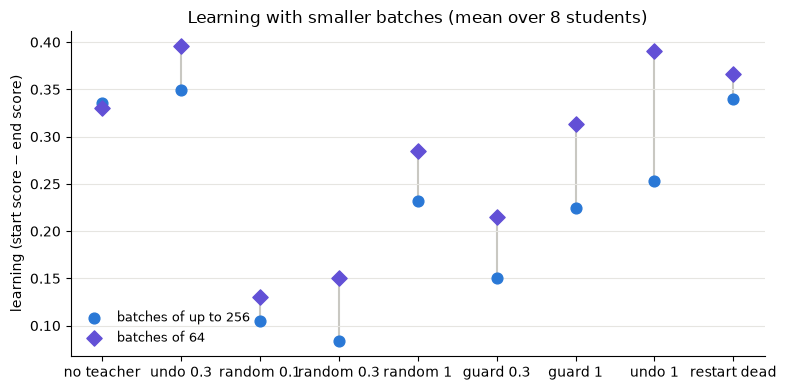

Batches of 64: per teacher

,pushes shown,solved as played,end solve rate,end solve rate se,learning,learning se
teacher,,,,,,
no teacher,0.000,0.224,0.239,0.007,0.330,0.022
undo 0.3,0.039,0.318,0.261,0.005,0.396,0.020
random 0.1,0.058,0.251,0.185,0.007,0.130,0.018
random 0.3,0.186,0.452,0.196,0.005,0.151,0.014
random 1,1.000,1.000,0.232,0.006,0.285,0.016
guard 0.3,0.035,0.319,0.212,0.009,0.215,0.026
guard 1,0.172,0.949,0.249,0.005,0.313,0.013
undo 1,0.391,0.894,0.272,0.006,0.391,0.015


Batches of 64: end score, row minus column, paired by student (below 0: the row's students learned more):

,no teacher,undo 0.3,random 0.1,random 0.3,random 1,guard 0.3,guard 1,undo 1
no teacher,,+0.07 ± 0.03 (1/8),-0.20 ± 0.03 (8/8),-0.18 ± 0.03 (8/8),-0.04 ± 0.03 (7/8),-0.12 ± 0.03 (8/8),-0.02 ± 0.02 (6/8),+0.06 ± 0.03 (2/8)
undo 0.3,-0.07 ± 0.03 (7/8),,-0.27 ± 0.03 (8/8),-0.25 ± 0.02 (8/8),-0.11 ± 0.03 (7/8),-0.18 ± 0.03 (8/8),-0.08 ± 0.02 (8/8),-0.00 ± 0.03 (5/8)
random 0.1,+0.20 ± 0.03 (0/8),+0.27 ± 0.03 (0/8),,+0.02 ± 0.02 (3/8),+0.15 ± 0.02 (0/8),+0.08 ± 0.02 (0/8),+0.18 ± 0.02 (0/8),+0.26 ± 0.02 (0/8)
random 0.3,+0.18 ± 0.03 (0/8),+0.25 ± 0.02 (0/8),-0.02 ± 0.02 (5/8),,+0.13 ± 0.01 (0/8),+0.06 ± 0.03 (1/8),+0.16 ± 0.02 (0/8),+0.24 ± 0.02 (0/8)
random 1,+0.04 ± 0.03 (1/8),+0.11 ± 0.03 (1/8),-0.15 ± 0.02 (8/8),-0.13 ± 0.01 (8/8),,-0.07 ± 0.03 (7/8),+0.03 ± 0.02 (3/8),+0.11 ± 0.02 (0/8)
guard 0.3,+0.12 ± 0.03 (0/8),+0.18 ± 0.03 (0/8),-0.08 ± 0.02 (8/8),-0.06 ± 0.03 (7/8),+0.07 ± 0.03 (1/8),,+0.10 ± 0.02 (0/8),+0.18 ± 0.02 (0/8)
guard 1,+0.02 ± 0.02 (2/8),+0.08 ± 0.02 (0/8),-0.18 ± 0.02 (8/8),-0.16 ± 0.02 (8/8),-0.03 ± 0.02 (5/8),-0.10 ± 0.02 (8/8),,+0.08 ± 0.02 (1/8)
undo 1,-0.06 ± 0.03 (6/8),+0.00 ± 0.03 (3/8),-0.26 ± 0.02 (8/8),-0.24 ± 0.02 (8/8),-0.11 ± 0.02 (8/8),-0.18 ± 0.02 (8/8),-0.08 ± 0.02 (7/8),


In [8]:
even, b64 = sa.load("shortcut_even"), sa.load("shortcut_b64")
if even is None or b64 is None:
    print("the batch runs haven't finished")
else:
    print("Equal batches: learning with default and equal batches; difference = equal minus default, paired by student:")
    display(sa.cross_run_table(runs["all"], even))
    table = sa.cross_run_table(runs["all"], b64)
    print("Batches of 64: learning with default batches and batches of 64; difference = 64 minus default:")
    display(table)
    fig, ax = plt.subplots(figsize=(8, 4))
    sa.plot_cross_run(ax, table, "batches of up to 256", "batches of 64")
    ax.set_title("Learning with smaller batches (mean over 8 students)")
    fig.tight_layout()
    fig.savefig(f"{FIGURES}/batches.png", dpi=130)
    plt.show()
    print("Batches of 64: per teacher")
    B64 = ["none", "undo:0.3", "random:0.1", "random:0.3", "random:1", "guard:0.3", "guard:1", "undo:1"]
    display(sa.teacher_table(b64).loc[[sa.teacher_name(t) for t in B64]])
    print("Batches of 64: end score, row minus column, paired by student (below 0: the row's students learned more):")
    display(sa.paired_table(b64, B64))

## A Bayesian teacher

`teach.Bayes` ports Rush Hour's simplest Bayesian teacher (`scripts/teach.py` `Bayesian3`). It holds a model of the
student, fitted from what the student does:

- its chance of playing an optimal push at each distance to solved (1-10, 11+), around an overall level;
- how hard the current level is for it, updated after each of its own pushes;
- what a mistake does at each distance: deadlock the level, move it further from solved (by 1, 2, or 3+ pushes), or
  leave it as far;
- how fast its quick test notices a deadlock (at once, or after each further push), after which it restarts.

From this, backward induction over (pushes made, distance) forecasts the chance the student solves the level
untaught before its push cap. The teacher acts only while that forecast is below θ. `bayes-undo:θ` acts as the undo
teacher does, taking back a push that would deadlock the level, so every push played is the student's own. Like
undo q, it decides *whether* to act on a deadlocking push, but by its forecast rather than a coin. The runs are in
the batch-64 run (`shortcut_b64`), paired with its other teachers.

A 400-level probe on one student set θ. Spend is high even at low θ: once pushes run short, the forecast falls
below θ on most levels, and from then on every deadlocking push is taken back (θ 0.1: 18% of pushes, 0.5: 34%).
Matching undo 0.3's 3.9% would need θ near 0, where it acts only when an attempt is already lost. So θ 0.5 is
compared with undo 1 (39%) at about matched spend, and θ 0.1 sits between undo 0.3 and undo 1.

Two other rules use the same model:

- `bayes-restart:c` plans with restarts available: it sends the student back to the start whenever a fresh
  attempt now raises its chance of solving by more than c (here 0). In this model that happens on a deadlocked
  board the quick test missed, or on a board too far from solved for the pushes left. Plain `restart:inf` (restart
  on every deadlocked board) runs alongside it for comparison.
- `bayes-undo-value:b` is Rush Hour's original Bayesian rule: it takes a deadlocking push back only when its plan,
  which counts on its own later undos, says doing so raises the chance of solving by more than a cost per undo. The
  cost adjusts after every level so that a share b of the pushes are taken back: b = 0.04 matches undo 0.3's spend,
  and b = 0.18 matches bayes-undo 0.1's.

In the tables, "pushes shown" counts pushes taken back for undo rules and restarts forced for restart rules.

,pushes shown,solved as played,end solve rate,end solve rate se,learning,learning se
teacher,,,,,,
no teacher,0.000,0.224,0.239,0.007,0.330,0.022
undo 0.3,0.039,0.318,0.261,0.005,0.396,0.020
undo 1,0.391,0.894,0.272,0.006,0.391,0.015
bayes-undo 0.1,0.180,0.342,0.230,0.004,0.261,0.014
bayes-undo 0.5,0.312,0.707,0.251,0.008,0.332,0.025
restart dead,0.181,0.307,0.253,0.007,0.366,0.026
bayes-restart 0,0.187,0.314,0.269,0.004,0.418,0.015
bayes-undo-value 0.04,0.039,0.543,0.271,0.005,0.384,0.013
bayes-undo-value 0.18,0.178,0.831,0.266,0.008,0.364,0.026


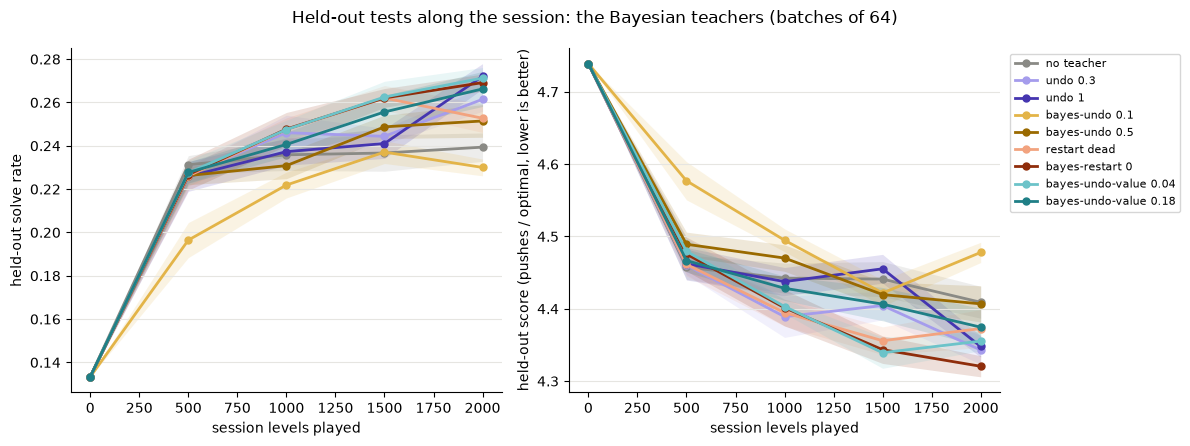

End score, row minus column, paired by student (below 0: the row's students learned more):

,no teacher,undo 0.3,undo 1,bayes-undo 0.1,bayes-undo 0.5,restart dead,bayes-restart 0,bayes-undo-value 0.04,bayes-undo-value 0.18
no teacher,,+0.07 ± 0.03 (1/8),+0.06 ± 0.03 (2/8),-0.07 ± 0.03 (7/8),+0.00 ± 0.03 (4/8),+0.04 ± 0.03 (5/8),+0.09 ± 0.02 (0/8),+0.05 ± 0.03 (2/8),+0.03 ± 0.03 (2/8)
undo 0.3,-0.07 ± 0.03 (7/8),,-0.00 ± 0.03 (5/8),-0.13 ± 0.03 (8/8),-0.06 ± 0.04 (5/8),-0.03 ± 0.03 (6/8),+0.02 ± 0.02 (2/8),-0.01 ± 0.03 (4/8),-0.03 ± 0.03 (4/8)
undo 1,-0.06 ± 0.03 (6/8),+0.00 ± 0.03 (3/8),,-0.13 ± 0.02 (8/8),-0.06 ± 0.03 (6/8),-0.02 ± 0.03 (5/8),+0.03 ± 0.03 (4/8),-0.01 ± 0.01 (4/8),-0.03 ± 0.02 (6/8)
bayes-undo 0.1,+0.07 ± 0.03 (1/8),+0.13 ± 0.03 (0/8),+0.13 ± 0.02 (0/8),,+0.07 ± 0.03 (1/8),+0.11 ± 0.03 (1/8),+0.16 ± 0.03 (0/8),+0.12 ± 0.02 (0/8),+0.10 ± 0.02 (0/8)
bayes-undo 0.5,-0.00 ± 0.03 (4/8),+0.06 ± 0.04 (3/8),+0.06 ± 0.03 (2/8),-0.07 ± 0.03 (7/8),,+0.03 ± 0.03 (3/8),+0.09 ± 0.03 (1/8),+0.05 ± 0.03 (2/8),+0.03 ± 0.03 (1/8)
restart dead,-0.04 ± 0.03 (3/8),+0.03 ± 0.03 (2/8),+0.02 ± 0.03 (3/8),-0.11 ± 0.03 (7/8),-0.03 ± 0.03 (5/8),,+0.05 ± 0.03 (2/8),+0.02 ± 0.02 (4/8),-0.00 ± 0.03 (5/8)
bayes-restart 0,-0.09 ± 0.02 (8/8),-0.02 ± 0.02 (6/8),-0.03 ± 0.03 (4/8),-0.16 ± 0.03 (8/8),-0.09 ± 0.03 (7/8),-0.05 ± 0.03 (6/8),,-0.03 ± 0.02 (6/8),-0.05 ± 0.03 (6/8)
bayes-undo-value 0.04,-0.05 ± 0.03 (6/8),+0.01 ± 0.03 (4/8),+0.01 ± 0.01 (4/8),-0.12 ± 0.02 (8/8),-0.05 ± 0.03 (6/8),-0.02 ± 0.02 (4/8),+0.03 ± 0.02 (2/8),,-0.02 ± 0.03 (6/8)
bayes-undo-value 0.18,-0.03 ± 0.03 (6/8),+0.03 ± 0.03 (4/8),+0.03 ± 0.02 (2/8),-0.10 ± 0.02 (8/8),-0.03 ± 0.03 (7/8),+0.00 ± 0.03 (3/8),+0.05 ± 0.03 (2/8),+0.02 ± 0.03 (2/8),


In [9]:
BAYES = [t for t in ["none", "undo:0.3", "undo:1", "bayes-undo:0.1", "bayes-undo:0.5", "restart:inf",
                      "bayes-restart:0", "bayes-undo-value:0.04", "bayes-undo-value:0.18"]
         if b64 is not None and len(b64["teachers"].get(t, {})) == 8]
if any(t.startswith("bayes") for t in BAYES):
    display(sa.teacher_table(b64).loc[[sa.teacher_name(t) for t in BAYES]])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    sa.plot_curves(axes[0], b64, "solve rate", BAYES)
    sa.plot_curves(axes[1], b64, "score", BAYES)
    axes[0].get_legend().remove()
    axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
    fig.suptitle("Held-out tests along the session: the Bayesian teachers (batches of 64)")
    fig.tight_layout()
    fig.savefig(f"{FIGURES}/curves_bayes.png", dpi=130)
    plt.show()
    print("End score, row minus column, paired by student (below 0: the row's students learned more):")
    display(sa.paired_table(b64, BAYES))
else:
    print("the Bayesian runs haven't finished")

## Only the optimal labels

A check on the labels. Shortcut labels give each board a solved attempt visited the first push of its shortest
route to solved through boards the attempt visited. In Sokoban those routes rarely join up, so in a wandering win
some labels are pushes that were not optimal: about 5% of labelled boards in a win near optimal, 12-13% in one over
twice optimal. `--optimal-labels 1` (`student.optimal_only`) asks the oracle and keeps only the target pushes that
are optimal, dropping boards left with none (7.5% of labelled boards in undo 1's wins); distance targets are kept.
Run `shortcut_b64_opt` repeats four teachers of the batch-64 run with only those labels, same students, levels and
seeds.

Learning with shortcut labels and with only their optimal pushes (batches of 64); difference = optimal only minus all, paired by student:

,pushes shown,learning,"learning, other",difference,difference se,students better
teacher,,,,,,
no teacher,0.000,0.330,0.447,0.117,0.016,8/8
undo 0.3,0.039,0.396,0.465,0.069,0.027,7/8
undo 1,0.401,0.391,0.454,0.063,0.019,8/8
bayes-undo 0.1,0.181,0.261,0.356,0.095,0.021,7/8


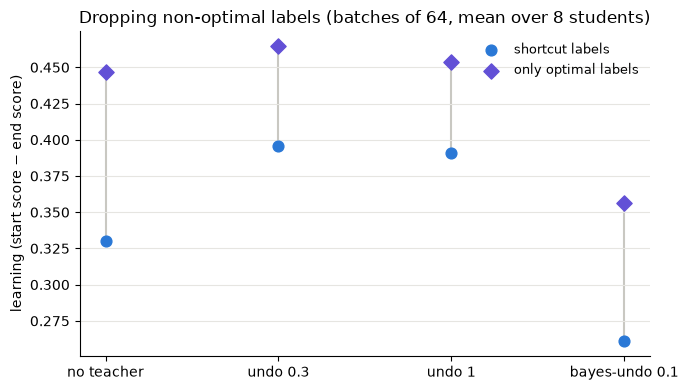

Only optimal labels: end score, row minus column, paired by student:

,no teacher,undo 0.3,undo 1,bayes-undo 0.1
no teacher,,+0.02 ± 0.02 (4/8),+0.01 ± 0.03 (3/8),-0.09 ± 0.03 (6/8)
undo 0.3,-0.02 ± 0.02 (4/8),,-0.01 ± 0.03 (2/8),-0.11 ± 0.03 (6/8)
undo 1,-0.01 ± 0.03 (5/8),+0.01 ± 0.03 (6/8),,-0.10 ± 0.02 (8/8)
bayes-undo 0.1,+0.09 ± 0.03 (2/8),+0.11 ± 0.03 (2/8),+0.10 ± 0.02 (0/8),


In [10]:
opt = sa.load("shortcut_b64_opt")
if opt is None or b64 is None:
    print("shortcut_b64_opt hasn't finished")
else:
    table = sa.cross_run_table(b64, opt)
    print("Learning with shortcut labels and with only their optimal pushes (batches of 64); difference = optimal "
          "only minus all, paired by student:")
    display(table)
    fig, ax = plt.subplots(figsize=(7, 4))
    sa.plot_cross_run(ax, table, "shortcut labels", "only optimal labels")
    ax.set_title("Dropping non-optimal labels (batches of 64, mean over 8 students)")
    fig.tight_layout()
    fig.savefig(f"{FIGURES}/optimal_labels.png", dpi=130)
    plt.show()
    print("Only optimal labels: end score, row minus column, paired by student:")
    display(sa.paired_table(opt))

## Rebalancing the examples by difficulty

Every teacher shifts the student's examples toward the hardest levels, where its extra and longest wins are, and
the easiest held-out levels slip in proportion. `--balance 0.30 0.28 0.23 0.18` (no teacher's shares of examples
by session bin, easiest first) weights each example by its bin's target share over the bin's share of the
examples so far this session (capped at 5, rescaled to average 1 per update), so that no teacher's help can crowd
out the easy levels. Run `shortcut_b64_bal` repeats four teachers of the batch-64 run with ordinary shortcut
labels, same students, levels and seeds.

Learning with and without rebalancing (batches of 64); difference = rebalanced minus not:

,pushes shown,learning,"learning, other",difference,difference se,students better
teacher,,,,,,
no teacher,0.000,0.330,0.368,0.038,0.025,7/8
undo 0.3,0.039,0.396,0.411,0.015,0.031,6/8
undo 1,0.398,0.391,0.363,-0.028,0.027,3/8
bayes-undo 0.1,0.184,0.261,0.309,0.048,0.016,7/8


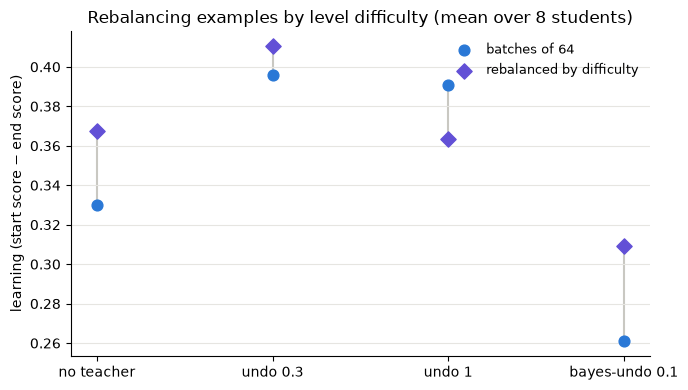

Rebalanced: end score, row minus column, paired by student:

,no teacher,undo 0.3,undo 1,bayes-undo 0.1
no teacher,,+0.04 ± 0.03 (2/8),-0.00 ± 0.03 (5/8),-0.06 ± 0.03 (6/8)
undo 0.3,-0.04 ± 0.03 (6/8),,-0.05 ± 0.02 (6/8),-0.10 ± 0.04 (7/8)
undo 1,+0.00 ± 0.03 (3/8),+0.05 ± 0.02 (2/8),,-0.05 ± 0.03 (6/8)
bayes-undo 0.1,+0.06 ± 0.03 (2/8),+0.10 ± 0.04 (1/8),+0.05 ± 0.03 (2/8),


In [11]:
bal = sa.load("shortcut_b64_bal")
if bal is None or b64 is None:
    print("shortcut_b64_bal hasn't finished")
else:
    table = sa.cross_run_table(b64, bal)
    print("Learning with and without rebalancing (batches of 64); difference = rebalanced minus not:")
    display(table)
    fig, ax = plt.subplots(figsize=(7, 4))
    sa.plot_cross_run(ax, table, "batches of 64", "rebalanced by difficulty")
    ax.set_title("Rebalancing examples by level difficulty (mean over 8 students)")
    fig.tight_layout()
    fig.savefig(f"{FIGURES}/balance.png", dpi=130)
    plt.show()
    print("Rebalanced: end score, row minus column, paired by student:")
    display(sa.paired_table(bal))

## Learning against help

The assistance-dilemma plot: learning against the share of pushes shown (log scale), one line per label setting, with
no teacher as a dashed line. A dilemma shows as a line that peaks and comes down before full help.

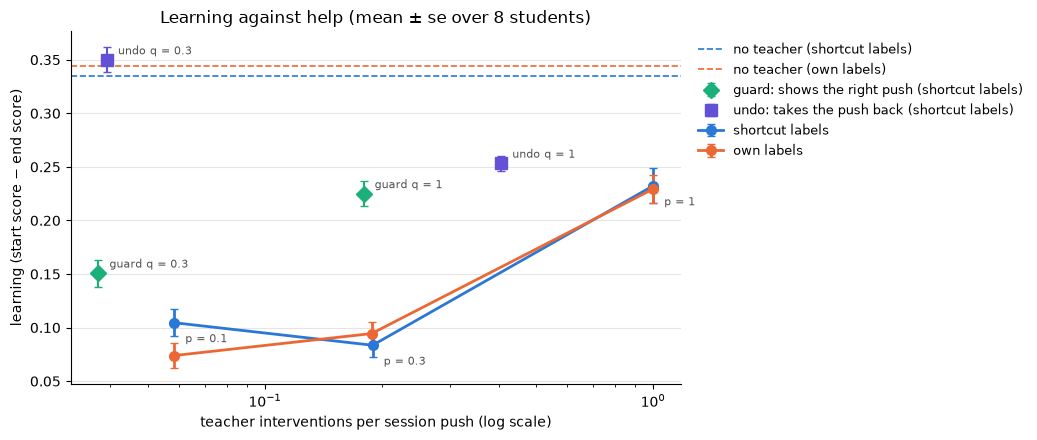

In [12]:
fig, ax = plt.subplots(figsize=(10.5, 4.5))
sa.plot_dilemma(ax, runs)
ax.set_title("Learning against help (mean ± se over 8 students)")
fig.tight_layout()
fig.savefig(f"{FIGURES}/dilemma.png", dpi=130)
plt.show()

## Conclusions

**Help costs learning here, at every level, and partial help costs most** (with the default batches of up to 256;
the batch-64 run below changes this). With shortcut labels, no teacher learns
+0.34 (held-out solve rate 0.13 to 0.25), random 0.1 +0.10, random 0.3 +0.08 and random 1 +0.23. Every comparison
holds for 8 of 8 students: no teacher beats every teacher, and full help beats both partial teachers. Random 0.3 nearly
doubles the levels solved during the session (0.43 against 0.22) and learns least. The gap opens early: at 500
levels random 0.1 is already at 0.16 against 0.21.

**This is a different shape from Rush Hour.** There, 30% help beat both none and 100% (the assistance dilemma, an
inverted U). Here learning against help is a U: the student does best alone, worst with a mix of its own play and
occasional shown pushes, and recovers part of the way with full demonstrations.

**The label setting makes no difference** (own labels: +0.34, +0.07, +0.09, +0.23, the same orderings 8/8). In Rush
Hour the dilemma came from shortcut labels, which make the student's own wandering worth learning from. In Sokoban,
pushes can't be undone and the student restarts on a detected deadlock, so the boards it visits rarely join up into
shortcuts. Shortcut labels add about 3 examples per solved level over the winning path (18.7 against 16.0). So Rush
Hour's mechanism has almost nothing to work with.

**A deadlock guard is the most efficient help, but still below no help.** Guard 1 steps in on 18% of pushes (the
student is about to deadlock the level that often), solves 95% of levels as played, and learns +0.22. That ties full
help (+0.23, 3/8 students better) at a fifth of the pushes shown, and it beats random 0.3 at the same spend (+0.08,
8/8). Guard 0.3 (3.7% shown, +0.15) beats random 0.1 (5.8%, +0.10, 7/8). Help aimed at the moments that end an
attempt costs learning far less than help at random moments. But no teacher still learns most (+0.34, 8/8 against
both guards). Even a guard that only blocks dead ends takes away something the student learns from. One guess: the
student's labels come from its solved attempts. Alone, it solves only levels its own play can handle, and every label
is a route it found itself. Guarded, it solves 95% of levels, including many it could not, and their labels follow
routes that worked only because the guard turned it away from dead ends it would have walked into. Those labels
describe play the student can't yet reproduce.

**Taking the push back instead of showing one removes the cost of help, but adds no benefit.** The undo teacher
catches the same deadlocking pushes as the guard but takes them back and lets the student choose again. Undo 0.3 steps
in as often as guard 0.3 (3.9% against 3.7% of pushes) and raises session solving just as much (0.31 against 0.22
alone), but learns +0.35 against the guard's +0.15 (8/8 students). That ties no teacher (+0.34, difference −0.01 ±
0.02, 6/8). Undo 1 learns +0.25, a little above guard 1 (+0.22, 6/8) and below no teacher (8/8). It solves 89% of
levels but takes back 14 pushes per level, and since the student never restarts, a solved attempt's labels span its
whole wandering route: 26 examples per solved level against 19 alone. This supports the guess about the guard: what
cost learning was the shown push, which steers the route and so the labels, not being rescued. But extra solved levels
made of the student's own play don't help either: undo 0.3 solves 41% more levels than no teacher, with labels as
clean, and learns the same. On these levels the student seems not to be short of examples, so help has little to add.
Harder levels, where it rarely wins alone, are the place to look for a benefit.

**Forced restarts tie no teacher, and trimming undo's wandering wins recovers half its gap.** A teacher that only
restarts the student on a board the oracle calls deadlocked (12 forced restarts per level: the quick test misses most
deadlocks for a while) raises session solving from 0.22 to 0.30 and learns +0.34, exactly no teacher's figure (4/8
students). Also restarting once a stretch can't finish within 1.5 × optimal changes nothing (+0.34, 0.28 solved): no
teacher's wins are already about 1.2 × optimal. Adding that stray restart to undo 1 shortens its labelled wins (22
examples per solved level against 26) and lifts learning from +0.25 to +0.29 (7/8 students), still below no teacher
(6/8). It also cuts the Adam steps per block from 8.6 to 6.2, so labels and step count changed together.

**Why the extra clean wins don't help: a fixed step budget.** Every update passes over its block's examples 3 times
in batches of up to 256, with Adam steps of roughly fixed size. No teacher's blocks (median 100 examples) and undo
0.3's or restart's (about 150) all get 3 steps per block, so more clean wins average into the same steps rather than
adding steps. Measured mid-session on this network, one block's update moves the weights the same distance with 100
or 250 examples (1.07 and 1.03 lr per weight), and 3.7 lr with batches of 64 (12 steps). Help that adds other
examples (shown pushes, long assisted routes) turns part of a fixed budget away from the student's own wins.

**Letting steps grow with examples lifts the teachers, and the undo teachers pass no teacher.** Two runs test the
budget, with the same students, levels and seeds. *Equal batches* (`shortcut_even`, Rush Hour's fix: a block of 517
splits 172/173/172 instead of 256/256/5) keep the step count and change little: guard 0.3 +0.15 → +0.16 (6/8), undo 1
+0.25 → +0.28 (4/8). *Batches of 64* (`shortcut_b64`, equal) give a block one step per 64 examples. No teacher gets
twice the steps (6.4 per block against 3.0) and learns the same (+0.34 → +0.33, 4/8), so more steps on the same
examples don't help by themselves. Teachers with bigger blocks get 3-3.5 times the steps and every one learns more:
undo 1 +0.25 → +0.39 (8/8), guard 1 +0.22 → +0.31 (8/8), random 0.3 +0.08 → +0.15 (8/8), guard 0.3 +0.15 → +0.21,
random 1 +0.23 → +0.29, undo 0.3 +0.35 → +0.40, random 0.1 +0.10 → +0.13. Within the batch-64 run, undo 0.3 (+0.40,
end score −0.07 ± 0.03 against no teacher, 7/8 students) and undo 1 (+0.39, −0.06 ± 0.03, 6/8) are the first teachers
to beat no teacher, though by only about two standard errors. Guard 1 ties it (+0.31, 2/8 better), random 1 is just
below (+0.29, 1/8). So the step budget explains why extra wins of the student's own added nothing: once each example
gets its share of steps, they help. It does not explain the cost of shown pushes: random 0.1 (+0.13), random 0.3
(+0.15) and guard 0.3 (+0.21) stay below no teacher for 8 of 8 students, with more steps than it. In this run
learning against help is no longer a plain U: the undo teachers sit above no teacher, while teachers that show pushes
sit below it, partial ones furthest.

**A Bayesian teacher that undoes deadlocks where the student is losing does worse than undoing at random.**
`teach.Bayes` ports Rush Hour's simplest Bayesian teacher: a fitted model of the student (skill per distance, this
level's difficulty updated push by push, what its mistakes do, how fast it notices a deadlock) forecasts its chance
of solving untaught, and it takes back deadlocking pushes only while that forecast is below θ. Its forecast is
roughly calibrated (on a 400-level probe with no teacher acting, levels forecast 0.15 were solved 0.12 of the time,
and those forecast 0.38 were solved 0.45), but its help goes to the wrong place for learning. With batches of 64,
θ 0.1 takes back 18% of pushes and learns +0.26, below no teacher (+0.33, 1/8 students better), undo 0.3 (+0.40,
0/8) and undo 1 (+0.39, 0/8). θ 0.5 takes back 31%, close to undo 1's 39%, and learns +0.33: it ties no teacher
(4/8) and falls below undo 1 (−0.06 ± 0.03, 2/8 better). The model sends help to the levels and moments where the
student is losing: θ 0.1 takes back 24 pushes per level on levels it forecast below 0.15, and 4 on those above
0.37. It lifts solving most on the hardest levels (20-25 pushes: 0.34 against 0.09 alone) and barely on the
easiest (0.40 against 0.39). Those rescued wins come late, after long wandering:
2.9 × optimal pushes per solved level against 2.4 alone, and 26 examples per solved level against 19. But long wins
are not what costs learning. Shortcut labels keep them mostly right: on wins of the starting network, 87-88% of
labelled boards in wins over 2 × optimal get an optimal push as their label, against 93-98% in wins within 1.25 ×,
and undo 1 has wins just as long and learns most. On held-out levels by difficulty, bayes-undo 0.1's students end
*worse* than no teacher's on the easiest levels (solve rate 0.33 against 0.39 at 8-11 pushes) and no better on the
hardest (0.14 against 0.13 at 20-25). Undo 1's give up a little on the easiest (0.35) but gain on every harder bin.
Why help aimed at the hardest moments costs the easy levels is open.

**The few wrong labels in a win cost a lot, for every teacher, but they don't explain the Bayesian teacher.**
Keeping only the shortcut labels the oracle calls optimal (`shortcut_b64_opt`, batches of 64) drops about 7% of
labelled boards and raises learning for all four teachers tested: no teacher +0.33 → +0.45 (8/8 students), undo 0.3
+0.40 → +0.46 (7/8), undo 1 +0.39 → +0.45 (8/8), bayes-undo 0.1 +0.26 → +0.36 (7/8). No teacher gains most, even
though its wins are the cleanest, and the undo teachers' edge over it disappears: the three tie (within ±0.02, 3-5
of 8 students). Bayes-undo 0.1 stays about 0.1 below all of them (2/8 students better than no teacher, 0/8 than
undo 1). So its deficit is not about label quality. One lead: every teacher shifts the student's examples toward
the hardest levels, where most extra wins and the longest ones are, and the easy levels slip. Among teachers that
show nothing, the smaller the easiest bin's share of examples, the bigger the loss there on held-out levels: no
teacher 30% of examples, undo 0.3 27% (−0.004 solve rate at 8-11 pushes against no teacher), undo 1 16% (−0.033),
bayes-undo 0.5 14% (−0.041), bayes-undo 0.1 17% (−0.054). Bayes-undo 0.1 has that shift with no more easy examples
than no teacher (5.8 per easy level against 5.1; undo 1 has 14.6), and in the batch-64 run it gained nothing on the
hardest levels to make up for it.

**Rebalancing by difficulty explains part of the Bayesian teacher's deficit.** Weighting each update so every
difficulty bin gets no teacher's share of the learning (`shortcut_b64_bal`) lifts bayes-undo 0.1 from +0.26 to +0.31
(+0.05 ± 0.02, 7/8 students), most of it on the easiest held-out levels (0.33 → 0.36, against no teacher's 0.39).
The other teachers barely move (no teacher +0.04 ± 0.03, undo 0.3 +0.02, undo 1 −0.03). Bayes-undo 0.1 still trails
no teacher by 0.06 (6/8) and undo 0.3 by 0.10 (7/8), so the shift toward hard levels is part of the problem, not
all of it.

**The same model of the student works when it restarts the student, or undoes where undoing pays.** Two other
rules on the Bayesian teacher's model, in the batch-64 run:

- *Planned restarts* (`bayes-restart:0`): it sends the student back to the start whenever a fresh attempt now
  raises the chance of solving (on a deadlocked board the quick test missed, or one too far from solved for the
  pushes left). It forces 12.7 restarts per level, about as many as restarting on every deadlock (12.3), and learns
  +0.42: the best teacher in the run. It beats no teacher for 8 of 8 students (end score −0.09 ± 0.02), plain
  restart on deadlock for 6 of 8 (+0.37; −0.05 ± 0.03), and ties undo 0.3 (6/8, −0.02 ± 0.02). Its students lose
  nothing on the easiest levels (0.40 against 0.39) and gain on every harder bin. Its wins look like no teacher's
  (19.5 examples per solved level, 2.4 × optimal pushes): more wins, not longer ones.
- *Value of undoing* (`bayes-undo-value:b`, Rush Hour's original Bayesian rule): it takes a deadlocking push back
  only when its plan says that raises the chance of solving by more than a cost, tuned to spend a share b of
  pushes. It hits its targets (3.9% and 17.8%) and places its undos far better for solving: at undo 0.3's spend it
  solves 54% of session levels against undo 0.3's 32%, and at bayes-undo 0.1's spend 83% against 34%. At equal
  spend it learns +0.36 against the threshold rule's +0.26 (+0.10, 8/8 students), and +0.38 at 3.9%, tying undo 0.3
  (4/8) and above no teacher (6/8, −0.05 ± 0.03).

So the threshold rule's flaw was where it put its help: on attempts already lost, near their end. Rules that act
where acting changes the outcome learn as much as the best simple teachers or more. Again, solving more during the
session does not mean learning more: undo-value at 3.9% solves 22 points more session levels than undo 0.3 and
learns the same, while the restart rule solves no more than restart on deadlock and learns more.

**Negative labels for dead ends make learning worse, not better.** Labelling the push before each detected deadlock
"not this push" (weight 1) drops learning everywhere: no teacher +0.34 → −0.08 (the student ends slightly worse than
it started), random 0.1 +0.10 → −0.01, random 0.3 +0.08 → +0.03, guard 0.3 +0.15 → +0.00. The ordering flips: no
teacher is now worst (0/8 against every teacher), because teachers that prevent deadlocks also prevent negatives. Two
reasons, both measured. *Blame is mostly wrong:* on 120 session levels with the starting network, 72% of blamed pushes
came from a board the oracle says was already deadlocked. The quick test noticed late, so an ordinary push took the
blame. *Negatives swamp positives:* about 5 negatives per level against 2.5 positive examples, and unlikelihood on a
push the student chose (often high probability) has a large gradient. The positive labels normally sharpen the policy
(normalised entropy at the start position 0.72 → 0.57, top-push probability 0.51 → 0.62). With negatives it stays
flat (0.70, 0.53), and the student solves fewer session levels (1,969 against 3,515 of 16,000), so it gets fewer
positives. So the guess that the student's dead ends go unused is not supported in this form. A cleaner test would
blame only the push that actually created the deadlock (oracle credit, an upper bound) and use a smaller weight.

**Why partial help hurts is still open.** Candidates:

- *Disconnected demonstrations.* At p = 0.1 the teacher barely raises solving (0.23 against 0.22) but adds about 3.7
  shown pushes to every unsolved level, so about half of what the student learns from is expert pushes on boards it
  then fails from. These may pull its policy away from what works for it. A one-student, 1,000-level probe that learned
  shown pushes only in solved attempts did not recover (0.20 against 0.21 with them, 0.225 with no teacher), but at
  ±0.03 it can't rule this out. `python sessions.py run ... --shown-unsolved 0` tests it with 8 students.
- *Credit for help.* Solved attempts with help label the student's own pushes along routes that worked only because
  the teacher stepped in at hard points.
- *The starting network* was pretrained with a teacher showing half the pushes. A student used to help might gain less
  from more of it than a self-taught one would.

**Caveats.** One starting network, one level distribution (Boxoban medium, 8-25 pushes) and only random teachers. The 8
students share their start and the test levels, differing only in level order and random draws, so the standard errors
(±0.01-0.02) say the orderings are reliable for this start, not across starts. The learning rate was chosen by a probe,
and there is no human data to calibrate against, unlike Rush Hour's people-calibrated students.